# Hotel Harmony: Data Insights for Optimized Operations
Elite Hotels International case study on the Kaggle *Hotel Booking Demand* dataset (`hotel_bookings.csv`, 119,390 bookings, 2015 to 2017). Python, Pandas, Matplotlib, Seaborn, SciPy, statsmodels, scikit-learn.

**Two versions of the data are used.** *All rows (119,390)* is the file as given, with only missing values filled (as the brief's hints compute it). *Cleaned (87,228)* removes 31,994 exact duplicate rows plus 168 invalid rows (no guests, one negative rate, one extreme rate). The data has no booking ID, so a duplicate row can be a genuine second booking; results are therefore shown for both, but duplicates inflate some figures a lot (see section 1).

In [1]:
import pandas as pd, numpy as np, seaborn as sns, matplotlib.pyplot as plt, warnings
from scipy import stats
import statsmodels.api as sm
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import cross_val_score, StratifiedKFold, train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.pipeline import make_pipeline
from sklearn.metrics import roc_auc_score, accuracy_score, confusion_matrix
warnings.filterwarnings('ignore'); sns.set_theme(style='whitegrid'); plt.rcParams['figure.dpi']=100
MONTHS=['January','February','March','April','May','June','July','August','September','October','November','December']
src = pd.read_csv('../data/hotel_bookings.csv')
print(src.shape)
src.head(3)

(119390, 32)


,hotel,is_canceled,lead_time,arrival_date_year,arrival_date_month,arrival_date_week_number,arrival_date_day_of_month,stays_in_weekend_nights,stays_in_week_nights,adults,...,deposit_type,agent,company,days_in_waiting_list,customer_type,adr,required_car_parking_spaces,total_of_special_requests,reservation_status,reservation_status_date
0,Resort Hotel,0,342,2015,July,27,1,0,0,2,...,No Deposit,NaN,NaN,0,Transient,0.0,0,0,Check-Out,2015-07-01
1,Resort Hotel,0,737,2015,July,27,1,0,0,2,...,No Deposit,NaN,NaN,0,Transient,0.0,0,0,Check-Out,2015-07-01
2,Resort Hotel,0,7,2015,July,27,1,0,1,1,...,No Deposit,NaN,NaN,0,Transient,75.0,0,0,Check-Out,2015-07-02


## 1. Data cleaning and preprocessing

In [2]:
miss = src.isna().sum(); print(miss[miss>0])
print('Exact duplicate rows:', int(src.duplicated().sum()))
guests = src.adults + src.children.fillna(0) + src.babies
print('Bookings with no guests:', int((guests==0).sum()), '| negative ADR:', int((src.adr<0).sum()), '| ADR >= 5000:', int((src.adr>=5000).sum()))
print('Reservation status values:', src.reservation_status.value_counts().to_dict())

children         4
country        488
agent        16340
company     112593
dtype: int64


Exact duplicate rows: 31994
Bookings with no guests: 180 | negative ADR: 1 | ADR >= 5000: 1
Reservation status values: {'Check-Out': 75166, 'Canceled': 43017, 'No-Show': 1207}


**Decisions**
- `children` (4 missing) is filled with 0; `country` (488 missing) becomes `Unknown`; `agent` (16,340 missing) means no travel agent was used (kept as missing for counting, filled with 0 for modelling); `company` (112,593 missing, 94%) is mostly empty and is not used.
- `arrival_date_*` columns are combined into a datetime `arrival`; `reservation_status_date` is converted to a date.
- `reservation_status` and its date record the *outcome* of the booking, so they are never used as predictors.
- Duplicates are shown both ways. The cleaned set also drops bookings with no guests (166 unique rows), the one negative ADR and the one ADR of 5,400.

In [3]:
def prep(d):
    d=d.copy(); d['children']=d.children.fillna(0); d['country']=d.country.fillna('Unknown')
    d['nights']=d.stays_in_weekend_nights+d.stays_in_week_nights
    d['month_n']=d.arrival_date_month.map({m:i+1 for i,m in enumerate(MONTHS)})
    d['arrival']=pd.to_datetime(dict(year=d.arrival_date_year,month=d.month_n,day=d.arrival_date_day_of_month))
    d['reservation_status_date']=pd.to_datetime(d.reservation_status_date)
    d['revenue']=np.where(d.is_canceled==0,d.adr*d.nights,0)      # realised room revenue of stays that happened
    return d
raw = prep(src)
u = src.drop_duplicates(); ok = ((u.adults+u.children.fillna(0)+u.babies)>0) & (u.adr>=0) & (u.adr<5000)
data = prep(u[ok])
print('All rows:', len(raw), '| Cleaned:', len(data))
data.to_csv('../data/hotel_bookings_cleaned.csv', index=False)

All rows: 119390 | Cleaned: 87228


In [4]:
# Why duplicates matter: cancellation rate by market segment, all rows vs cleaned
pd.DataFrame({'All rows %':raw.groupby('market_segment').is_canceled.mean()*100,'Cleaned %':data.groupby('market_segment').is_canceled.mean()*100,
 'All rows n':raw.groupby('market_segment').size(),'Cleaned n':data.groupby('market_segment').size()}).round(1)

,All rows %,Cleaned %,All rows n,Cleaned n
market_segment,,,,
Aviation,21.9,19.9,237,226
Complementary,13.1,12.3,743,692
Corporate,18.7,12.1,5295,4200
Direct,15.3,14.7,12606,11780
Groups,61.1,27.1,19811,4921
Offline TA/TO,34.3,14.8,24219,13854
Online TA,36.7,35.4,56477,51553
Undefined,100.0,100.0,2,2


## 2. Basic questions

In [5]:
def two(fn):
    return pd.Series({'All rows (119,390)':fn(raw),'Cleaned (87,228)':fn(data)})
print('Q1 average lead time (days)'); display(two(lambda d: round(d.lead_time.mean(),1)))
print('Q3 canceled bookings'); display(two(lambda d: int(d.is_canceled.sum())))
print('Q3 cancellation rate %'); display(two(lambda d: round(d.is_canceled.mean()*100,1)))
print('Q5 average special requests per booking'); display(two(lambda d: round(d.total_of_special_requests.mean(),3)))
print('Q8 % bookings needing parking'); display(two(lambda d: round((d.required_car_parking_spaces>0).mean()*100,1)))
print('Q10 bookings through travel agents (agent not null)'); display(two(lambda d: int(d.agent.notna().sum())))

Q1 average lead time (days)


All rows (119,390)    104.0
Cleaned (87,228)       80.0
dtype: float64

Q3 canceled bookings


All rows (119,390)    44224
Cleaned (87,228)      24008
dtype: int64

Q3 cancellation rate %


All rows (119,390)    37.0
Cleaned (87,228)      27.5
dtype: float64

... (2 outputs left out)

Q8 % bookings needing parking


All rows (119,390)    6.2
Cleaned (87,228)      8.4
dtype: float64

Q10 bookings through travel agents (agent not null)


All rows (119,390)    103050
Cleaned (87,228)       75087
dtype: int64

,All rows,Cleaned
hotel,,
City Hotel,79330,53273
Resort Hotel,40060,33955


,All rows,Cleaned
arrival_date_month,,
August,13877,11242
July,12661,10043
May,11791,8344


,All rows,Cleaned
country,,
PRT,48590,27354
GBR,12129,10423
FRA,10415,8823
ESP,8568,7244
DEU,7287,5385


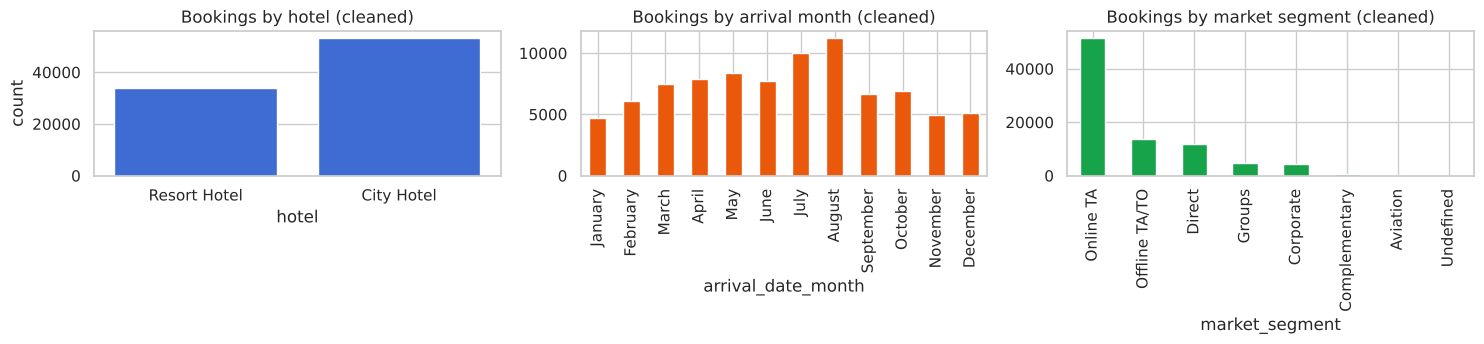

In [6]:
# Q2 distribution by hotel type
display(pd.DataFrame({'All rows':raw.hotel.value_counts(),'Cleaned':data.hotel.value_counts()}))
# Q4 most common arrival month and Q6 top countries
display(pd.DataFrame({'All rows':raw.arrival_date_month.value_counts().head(3),'Cleaned':data.arrival_date_month.value_counts().head(3)}))
display(pd.DataFrame({'All rows':raw.country.value_counts().head(5),'Cleaned':data.country.value_counts().head(5)}))
fig,ax=plt.subplots(1,3,figsize=(15,3.6))
sns.countplot(x='hotel',data=data,ax=ax[0],color='#2563eb'); ax[0].set_title('Bookings by hotel (cleaned)')
data.arrival_date_month.value_counts().reindex(MONTHS).plot.bar(ax=ax[1],color='#ea580c'); ax[1].set_title('Bookings by arrival month (cleaned)')
data.market_segment.value_counts().plot.bar(ax=ax[2],color='#16a34a'); ax[2].set_title('Bookings by market segment (cleaned)'); plt.tight_layout(); plt.show()

In [7]:
# Q7 ADR by hotel type, Q9 average nights
display(pd.DataFrame({'All rows':raw.groupby('hotel').adr.mean(),'Cleaned':data.groupby('hotel').adr.mean()}).round(2))
display(pd.DataFrame({'All rows':[raw.stays_in_week_nights.mean(),raw.stays_in_weekend_nights.mean()],'Cleaned':[data.stays_in_week_nights.mean(),data.stays_in_weekend_nights.mean()]},index=['Week nights','Weekend nights']).round(2))

,All rows,Cleaned
hotel,,
City Hotel,105.30,111.17
Resort Hotel,94.95,99.06


,All rows,Cleaned
Week nights,2.50,2.62
Weekend nights,0.93,1.00


## 3. Medium questions

In [8]:
# M1 cancellation rate by hotel; M5 previous cancellations by hotel
display(pd.DataFrame({'Cancel % (all rows)':raw.groupby('hotel').is_canceled.mean()*100,'Cancel % (cleaned)':data.groupby('hotel').is_canceled.mean()*100,
  'Avg previous cancellations (all rows)':raw.groupby('hotel').previous_cancellations.mean(),'Avg previous cancellations (cleaned)':data.groupby('hotel').previous_cancellations.mean()}).round(3))

,Cancel % (all rows),Cancel % (cleaned),Avg previous cancellations (all rows),Avg previous cancellations (cleaned)
hotel,,,,
City Hotel,41.727,30.098,0.080,0.036
Resort Hotel,27.763,23.484,0.102,0.022


,ADR (all rows),ADR (cleaned),n (cleaned)
market_segment,,,
Aviation,100.1,100.6,226
Complementary,2.9,3.1,692
Corporate,69.4,68.3,4200
Direct,115.4,116.8,11780
Groups,79.5,75.2,4921
Offline TA/TO,87.4,81.6,13854
Online TA,117.2,118.3,51553
Undefined,15.0,15.0,2


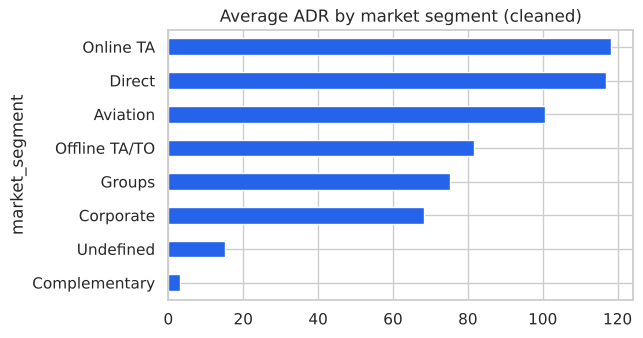

In [9]:
# M2 average ADR per market segment
display(pd.DataFrame({'ADR (all rows)':raw.groupby('market_segment').adr.mean(),'ADR (cleaned)':data.groupby('market_segment').adr.mean(),'n (cleaned)':data.groupby('market_segment').size()}).round(1))
data.groupby('market_segment').adr.mean().sort_values().plot.barh(color='#2563eb',figsize=(6,3.5)); plt.title('Average ADR by market segment (cleaned)'); plt.show()

All rows: correlation lead_time vs is_canceled = 0.293 (p = 0)


,count,cancel %
lead_time,,
0-14,26772,12.9
15-30,11934,31.3
31-90,29553,37.7
91-180,26439,44.7
181-365,21544,55.5
365+,3148,67.7


Cleaned: correlation lead_time vs is_canceled = 0.185 (p = 0)


,count,cancel %
lead_time,,
0-14,24377,11.5
15-30,10152,28.3
31-90,22719,32.0
91-180,18224,35.0
181-365,11192,39.7
365+,564,40.8


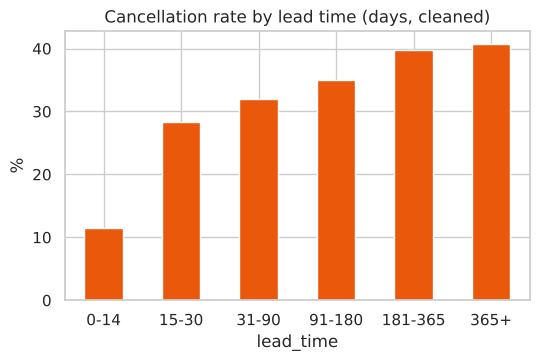

In [10]:
# M3 lead time vs cancellation
for nm,d in (('All rows',raw),('Cleaned',data)):
    r,p=stats.pointbiserialr(d.is_canceled,d.lead_time); print(f'{nm}: correlation lead_time vs is_canceled = {r:.3f} (p = {p:.2g})')
    lb=pd.cut(d.lead_time,[-1,14,30,90,180,365,1000],labels=['0-14','15-30','31-90','91-180','181-365','365+'])
    display((d.groupby(lb,observed=True).is_canceled.agg(['count','mean'])*[1,100]).round(1).rename(columns={'mean':'cancel %'}))
lb=pd.cut(data.lead_time,[-1,14,30,90,180,365,1000],labels=['0-14','15-30','31-90','91-180','181-365','365+'])
(data.groupby(lb,observed=True).is_canceled.mean()*100).plot.bar(color='#ea580c',figsize=(6,3.5)); plt.title('Cancellation rate by lead time (days, cleaned)'); plt.ylabel('%'); plt.xticks(rotation=0); plt.show()

In [11]:
# M4 distribution channel
display(pd.DataFrame({'All rows':raw.distribution_channel.value_counts(),'Cleaned':data.distribution_channel.value_counts()}))

,All rows,Cleaned
distribution_channel,,
TA/TO,97870,69027
Direct,14645,12953
Corporate,6677,5062
GDS,193,181
Undefined,5,5


,ADR all rows,ADR cleaned,Bookings (cleaned)
arrival_date_year,,,
2015,87.18,92.36,13284
2016,98.33,101.57,42312
2017,114.64,118.92,31632


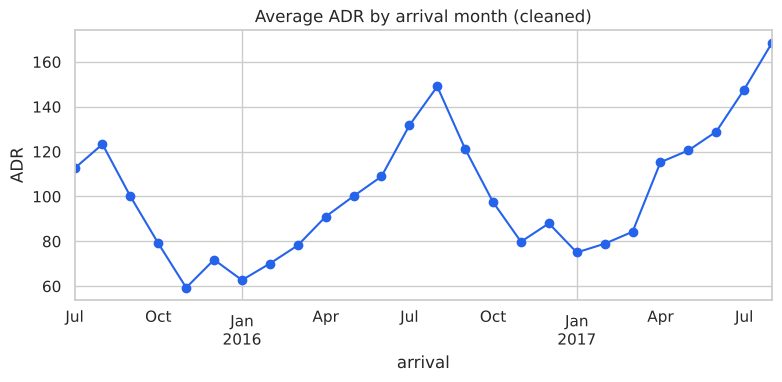

In [12]:
# M6 ADR trend: by year and by month
display(pd.DataFrame({'ADR all rows':raw.groupby('arrival_date_year').adr.mean(),'ADR cleaned':data.groupby('arrival_date_year').adr.mean(),'Bookings (cleaned)':data.groupby('arrival_date_year').size()}).round(2))
ts=data.groupby(data.arrival.dt.to_period('M')).adr.mean(); ts.index=ts.index.to_timestamp()
ts.plot(figsize=(9,3.5),marker='o',color='#2563eb'); plt.title('Average ADR by arrival month (cleaned)'); plt.ylabel('ADR'); plt.show()

*Note:* 2015 covers July to December only and 2017 January to August only, so yearly averages mix different seasons; the monthly line shows the seasonal pattern clearly.

,Sum of ADR (all rows),Sum of ADR (cleaned),Realised revenue (cleaned)
arrival_date_month,,,
January,417172.0,328720.0,705020.0
February,593662.0,455380.0,1024202.0
March,790176.0,607640.0,1415735.0
April,1113123.0,819232.0,1804557.0
May,1281629.0,928738.0,2059809.0
June,1276277.0,929669.0,2295647.0
July,1605263.0,1362972.0,3798500.0
August,1944328.0,1698164.0,4606618.0
September,1103862.0,749798.0,1969859.0


Highest month: {'Sum of ADR (all rows)': 'August', 'Sum of ADR (cleaned)': 'August', 'Realised revenue (cleaned)': 'August'}


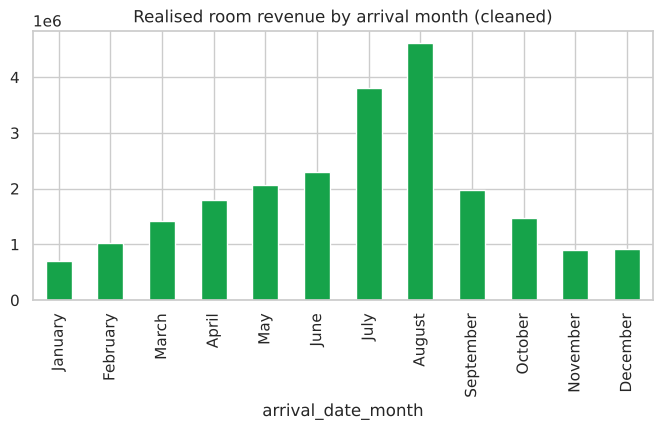

In [13]:
# M7 month with highest revenue: (a) the brief's hint (sum of ADR), (b) realised room revenue = ADR x nights for stays that were not canceled
res=pd.DataFrame({'Sum of ADR (all rows)':raw.groupby('arrival_date_month').adr.sum(),'Sum of ADR (cleaned)':data.groupby('arrival_date_month').adr.sum(),'Realised revenue (cleaned)':data.groupby('arrival_date_month').revenue.sum()}).reindex(MONTHS).round(0)
display(res); print('Highest month:', res.idxmax().to_dict())
res['Realised revenue (cleaned)'].plot.bar(color='#16a34a',figsize=(8,3.5)); plt.title('Realised room revenue by arrival month (cleaned)'); plt.show()

In [14]:
# M8 special requests vs ADR
for nm,d in (('All rows',raw),('Cleaned',data)):
    print(nm,'correlation special requests vs ADR =',round(d.total_of_special_requests.corr(d.adr),3))
display(data.groupby('total_of_special_requests').adr.agg(['count','mean']).round(1))
print('Cancellation rate by special requests (cleaned):'); display((data.groupby('total_of_special_requests').is_canceled.mean()*100).round(1))

All rows correlation special requests vs ADR = 0.172
Cleaned correlation special requests vs ADR = 0.146


,count,mean
total_of_special_requests,,
0,43787,99.8
1,28976,109.8
2,11795,118.7
3,2314,125.2
4,320,131.1
5,36,130.0


Cancellation rate by special requests (cleaned):


total_of_special_requests
0    33.3
1    22.4
2    21.3
3    17.1
4    10.6
5     5.6
Name: is_canceled, dtype: float64

In [15]:
# M9 stay duration, repeated vs new guests
display(pd.DataFrame({'Avg nights (all rows)':raw.groupby('is_repeated_guest').nights.mean(),'Avg nights (cleaned)':data.groupby('is_repeated_guest').nights.mean(),'Bookings (cleaned)':data.groupby('is_repeated_guest').size()}).round(2).rename(index={0:'New guests',1:'Repeated guests'}))
# M10 reserved room type
display(pd.DataFrame({'All rows':raw.reserved_room_type.value_counts().head(5),'Cleaned':data.reserved_room_type.value_counts().head(5)}))

,Avg nights (all rows),Avg nights (cleaned),Bookings (cleaned)
is_repeated_guest,,,
New guests,3.48,3.70,83865
Repeated guests,1.93,1.95,3363


,All rows,Cleaned
reserved_room_type,,
A,85994,56434
D,19201,17376
E,6535,6036
F,2897,2820
G,2094,2050


## 4. Advanced questions

In [16]:
# A1 factors behind cancellation: logistic regression on the cleaned data (outcome columns are NOT used as predictors)
num=['lead_time','booking_changes','total_of_special_requests','previous_cancellations','previous_bookings_not_canceled','days_in_waiting_list','adr','nights','adults','children','babies','required_car_parking_spaces','is_repeated_guest']
cat=['hotel','deposit_type','customer_type','market_segment']
X=data[num+cat]; y=data.is_canceled
pre=ColumnTransformer([('n',StandardScaler(),num),('c',OneHotEncoder(drop='first',handle_unknown='ignore'),cat)])
pipe=make_pipeline(pre,LogisticRegression(max_iter=3000))
cv=StratifiedKFold(5,shuffle=True,random_state=42)
print('5-fold CV AUC:',round(cross_val_score(pipe,X,y,cv=cv,scoring='roc_auc').mean(),3),'| CV accuracy:',round(cross_val_score(pipe,X,y,cv=cv,scoring='accuracy').mean(),3))
Xtr,Xte,ytr,yte=train_test_split(X,y,test_size=.25,random_state=42,stratify=y); pipe.fit(Xtr,ytr)
print('Hold-out accuracy:',round(accuracy_score(yte,pipe.predict(Xte)),3),'| AUC:',round(roc_auc_score(yte,pipe.predict_proba(Xte)[:,1]),3)); print(confusion_matrix(yte,pipe.predict(Xte)))
pipe.fit(X,y); names=pipe[0].get_feature_names_out(); co=pd.DataFrame({'coef':pipe[-1].coef_[0],'odds ratio':np.exp(pipe[-1].coef_[0])},index=names).round(3)
co.index=[i.split('__')[1] for i in co.index]; display(co.reindex(co.coef.abs().sort_values(ascending=False).index).head(14))

5-fold CV AUC: 0.795 | CV accuracy: 0.785


Hold-out accuracy: 0.785 | AUC: 0.799
[[14808   997]
 [ 3685  2317]]


,coef,odds ratio
required_car_parking_spaces,-4.836,0.008
deposit_type_Non Refund,3.813,45.296
market_segment_Offline TA/TO,-0.991,0.371
customer_type_Transient,0.745,2.107
deposit_type_Refundable,0.725,2.064
previous_cancellations,0.678,1.970
market_segment_Online TA,0.625,1.867
total_of_special_requests,-0.555,0.574
market_segment_Undefined,0.544,1.723
previous_bookings_not_canceled,-0.515,0.597


In [17]:
# The deposit_type effect: check it against the raw rates
print((data.groupby('deposit_type').is_canceled.agg(['count','mean'])*[1,100]).round(1))
print('All rows:'); print((raw.groupby('deposit_type').is_canceled.agg(['count','mean'])*[1,100]).round(1))

              count  mean
deposit_type             
No Deposit    86084  26.7
Non Refund     1037  94.7
Refundable      107  24.3
All rows:
               count  mean
deposit_type              
No Deposit    104641  28.4
Non Refund     14587  99.4
Refundable       162  22.2


**Read the deposit result with care.** Bookings labelled *Non Refund* cancel about 95% to 99% of the time, which is the opposite of what a real non-refundable deposit should do. This is a known quirk of this dataset, so *Non Refund* is a strong statistical predictor but should not be read as "deposits cause cancellations" or used to recommend non-refundable deposits.

In [18]:
# A2 ADR vs number of adults, children, babies (multiple regression, cleaned)
ols=sm.OLS(data.adr,sm.add_constant(data[['adults','children','babies']])).fit()
display(pd.DataFrame({'coef':ols.params,'std err':ols.bse,'p-value':ols.pvalues}).round(3)); print('R-squared:',round(ols.rsquared,3),'| n =',int(ols.nobs))

,coef,std err,p-value
const,62.118,0.508,0.0
adults,20.698,0.256,0.0
children,38.648,0.349,0.0
babies,6.722,1.398,0.0


R-squared: 0.181 | n = 87228


In [19]:
# A3 booking changes vs special requests (proxy only: the data has no guest-satisfaction score)
for nm,d in (('All rows',raw),('Cleaned',data)):
    print(nm,'Pearson',round(d.booking_changes.corr(d.total_of_special_requests),3),'| Spearman',round(d.booking_changes.corr(d.total_of_special_requests,method='spearman'),3))
display(data.groupby(data.booking_changes.clip(upper=4)).total_of_special_requests.agg(['count','mean']).round(3))

All rows Pearson 0.053 | Spearman 0.042
Cleaned Pearson 0.018 | Spearman -0.004


,count,mean
booking_changes,,
0,71425,0.697
1,10867,0.683
2,3482,0.738
3,862,0.835
4,592,0.845


,All rows %,Cleaned %
arrival_date_month,,
January,30.5,22.1
February,33.4,23.2
March,32.2,24.4
April,40.8,30.5
May,39.7,29.3
June,41.5,30.3
July,37.5,31.8
August,37.8,32.2
September,39.2,24.6


,All rows %,Cleaned %
season,,
Autumn,36.8,23.3
Spring,37.8,28.1
Summer,38.7,31.6
Winter,33.1,24.1


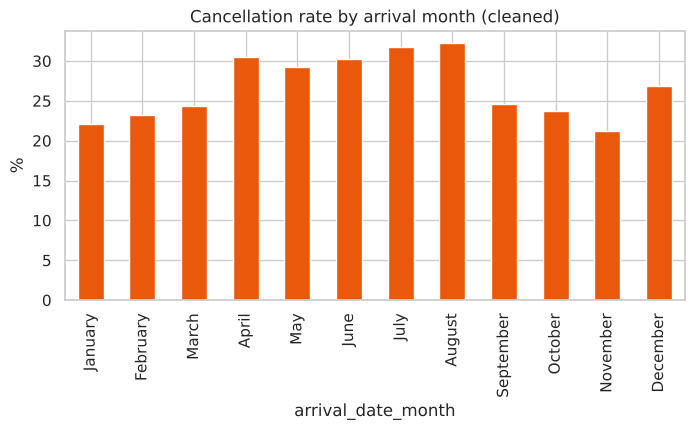

In [20]:
# A4 seasonal impact on cancellations
mc=pd.DataFrame({'All rows %':raw.groupby('arrival_date_month').is_canceled.mean()*100,'Cleaned %':data.groupby('arrival_date_month').is_canceled.mean()*100}).reindex(MONTHS).round(1); display(mc)
season={12:'Winter',1:'Winter',2:'Winter',3:'Spring',4:'Spring',5:'Spring',6:'Summer',7:'Summer',8:'Summer',9:'Autumn',10:'Autumn',11:'Autumn'}
sd=data.assign(season=data.month_n.map(season)); raws=raw.assign(season=raw.month_n.map(season))
display(pd.DataFrame({'All rows %':raws.groupby('season').is_canceled.mean()*100,'Cleaned %':sd.groupby('season').is_canceled.mean()*100}).round(1))
mc['Cleaned %'].plot.bar(color='#ea580c',figsize=(8,3.5)); plt.title('Cancellation rate by arrival month (cleaned)'); plt.ylabel('%'); plt.show()

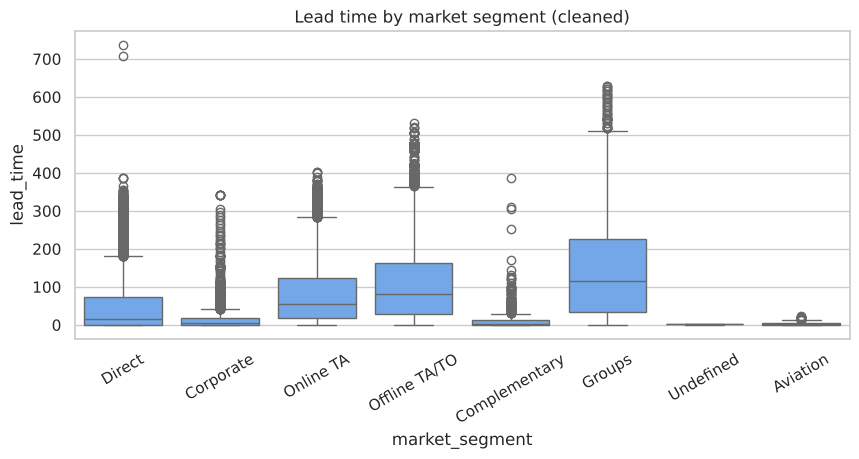

,count,mean,25%,50%,75%,max
market_segment,,,,,,
Aviation,226.0,4.0,1.0,3.0,6.0,23.0
Complementary,692.0,14.0,0.0,3.0,12.0,386.0
Corporate,4200.0,16.0,1.0,5.0,17.0,343.0
Direct,11780.0,49.0,1.0,15.0,73.0,737.0
Groups,4921.0,148.0,35.0,115.0,227.0,629.0
Offline TA/TO,13854.0,106.0,28.0,82.0,163.0,532.0
Online TA,51553.0,80.0,17.0,55.0,124.0,403.0
Undefined,2.0,2.0,1.0,2.0,2.0,2.0


In [21]:
# A5 lead time distribution by market segment
plt.figure(figsize=(10,4)); sns.boxplot(x='market_segment',y='lead_time',data=data,color='#60a5fa'); plt.xticks(rotation=30); plt.title('Lead time by market segment (cleaned)'); plt.show()
display(data.groupby('market_segment').lead_time.describe()[['count','mean','25%','50%','75%','max']].round(0))

## 5. Insights and recommendations
- **Cancellations:** 37.0% on the file as given but 27.5% once duplicates are removed. City Hotel cancels more than Resort Hotel on both bases.
- **Lead time** is the clearest driver: cancellation climbs from about 12% for bookings made within 14 days to about 40% for bookings made a year or more ahead (cleaned data).
- **Segments:** Online TA has the highest cancellation rate on the cleaned data (35%); Groups and Offline TA/TO fall sharply once duplicates are removed (27% and 15%).
- **Guest signals:** bookings that need parking never cancel; more special requests go with fewer cancellations and with a higher ADR.
- **Seasonality:** ADR peaks in July and August (especially for the Resort Hotel); the highest revenue months are August, July and June.
- **Limits:** no booking ID, no satisfaction score, no occupancy or room counts (so RevPAR cannot be computed), currency not stated; associations, not causes.